<a href="https://www.kaggle.com/code/youssefhazem75/traffic-signs-detection?scriptVersionId=353066253" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Traffic Sign Recognition Using YOLO and Vision Transformers

This project combines a **YOLO** object detection model trained on the **TT100K dataset** for real-time sign detection and spatial localization with a fine-tuned **Vision Transformer (ViT)** for high-precision multi-class sign classification. Designed to assist autonomous vehicles and Advanced Driver Assistance Systems (ADAS), the pipeline ensures rapid and reliable decision-making across complex road scenes. Building on foundational traffic sign benchmark research initiated by Stallkamp et al. (2012), the system addresses key real-world challenges such as detecting small traffic signs, handling class imbalance, and adapting to diverse lighting and environmental conditions.

## Environment Set Up

First let's make sure we have installed and loaded all needed packages.

In [2]:
!pip install accelerate transformers datasets wandb
!pip install ultralytics 

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 544.0 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 5.1 MB/s eta 0:00:00


In [3]:
import tensorflow as tf
import transformers
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import random
import torch
import cv2
from PIL import Image, ImageDraw

# TT100K Dataset Exploration

In [4]:
import os

DATA_ROOT = "/kaggle/input"

print("Available datasets:")
print(os.listdir(DATA_ROOT))

Available datasets:
['datasets']


In [5]:
DATA_ROOT = "/kaggle/input/datasets"

print("Datasets inside:")
print(os.listdir(DATA_ROOT))

Datasets inside:
['braunge']


In [6]:
BRAUNGE_ROOT = "/kaggle/input/datasets/braunge"

print(os.listdir(BRAUNGE_ROOT))

['tt100k']


In [7]:
TT100K_ROOT = "/kaggle/input/datasets/braunge/tt100k"

for root, dirs, files in os.walk(TT100K_ROOT):
    level = root.replace(TT100K_ROOT, "").count(os.sep)
    
    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")
        
        for file in files[:5]:
            print(f"{indent}    {file}")

tt100k/
    mydata/
        YOLOv5_TT100K.yaml
        YOLOv8_TT100K.yaml
        labels/
            val/
                62019.txt
                87220 (2).txt
                2869.txt
                3926.txt
                41137.txt
            train/
                84711.txt
                90459.txt
                12887 (4).txt
                31445.txt
                79153.txt
        images/
            val/
                64601.jpg
                16916.jpg
                3028 (2).jpg
                44758.jpg
                97120 (2).jpg
            train/
                38246.jpg
                25136 (3).jpg
                60205 (2).jpg
                80709 (3).jpg
                78573.jpg


## Dataset Configuration

In [9]:
import yaml

TT100K_ROOT = "/kaggle/input/datasets/braunge/tt100k/mydata"
YAML_PATH = f"{TT100K_ROOT}/YOLOv8_TT100K.yaml"

with open(YAML_PATH, "r") as f:
    config = yaml.safe_load(f)

print("Dataset configuration:\n")

for key, value in config.items():
    print(f"{key}: {value}")

Dataset configuration:

train: /kaggle/working/ultralytics/mydata/images/train
val: /kaggle/working/ultralytics/mydata/images/val
test: None
nc: 50
names: ['pl80', 'p6', 'ph', 'w', 'pa', 'p27', 'i5', 'p1', 'il70', 'p5', 'pm', 'p19', 'ip', 'p11', 'p13', 'p26', 'i2', 'pn', 'p10', 'p23', 'pbp', 'p3', 'p12', 'pne', 'i4', 'pb', 'pg', 'pr', 'pl5', 'pl10', 'pl15', 'pl20', 'pl25', 'pl30', 'pl35', 'pl40', 'pl50', 'pl60', 'pl65', 'pl70', 'pl90', 'pl100', 'pl110', 'pl120', 'il50', 'il60', 'il80', 'il90', 'il100', 'il110']


## Dataset Size and Composition

In [8]:
from pathlib import Path
from collections import Counter

TRAIN_IMG = Path(TT100K_ROOT) / "images/train"
VAL_IMG = Path(TT100K_ROOT) / "images/val"

TRAIN_LABEL = Path(TT100K_ROOT) / "labels/train"
VAL_LABEL = Path(TT100K_ROOT) / "labels/val"

image_extensions = [".jpg", ".jpeg", ".png", ".ppm"]

train_images = [p for p in TRAIN_IMG.iterdir() if p.suffix.lower() in image_extensions]
val_images = [p for p in VAL_IMG.iterdir() if p.suffix.lower() in image_extensions]

train_labels = list(TRAIN_LABEL.glob("*.txt"))
val_labels = list(VAL_LABEL.glob("*.txt"))

print("TT100K Dataset Summary")
print("----------------------")
print(f"Number of classes:     {config['nc']}")
print(f"Training images:       {len(train_images):,}")
print(f"Validation images:     {len(val_images):,}")
print(f"Total images:          {len(train_images) + len(val_images):,}")
print()
print(f"Training label files:  {len(train_labels):,}")
print(f"Validation label files:{len(val_labels):,}")
print(f"Total label files:     {len(train_labels) + len(val_labels):,}")
print()
print("Image formats:", Counter(p.suffix.lower() for p in train_images + val_images))

TT100K Dataset Summary
----------------------
Number of classes:     50
Training images:       20,594
Validation images:     3,627
Total images:          24,221

Training label files:  20,594
Validation label files:3,627
Total label files:     24,221

Image formats: Counter({'.jpg': 24221})


## Class Distribution

Total annotated traffic signs: 74,008
Number of classes: 50

Objects per class:
 0 | pl80   | 1,372
 1 | p6     | 770
 2 | ph     | 1,288
 3 | w      | 2,881
 4 | pa     | 624
 5 | p27    | 691
 6 | i5     | 3,038
 7 | p1     | 721
 8 | il70   | 1,123
 9 | p5     | 608
10 | pm     | 1,185
11 | p19    | 535
12 | ip     | 661
13 | p11    | 4,135
14 | p13    | 772
15 | p26    | 2,232
16 | i2     | 1,830
17 | pn     | 7,554
18 | p10    | 1,079
19 | p23    | 813
20 | pbp    | 794
21 | p3     | 1,402
22 | p12    | 771
23 | pne    | 4,799
24 | i4     | 2,397
25 | pb     | 683
26 | pg     | 540
27 | pr     | 542
28 | pl5    | 1,504
29 | pl10   | 1,165
30 | pl15   | 1,185
31 | pl20   | 1,289
32 | pl25   | 1,091
33 | pl30   | 1,532
34 | pl35   | 1,100
35 | pl40   | 1,783
36 | pl50   | 1,495
37 | pl60   | 1,224
38 | pl65   | 1,052
39 | pl70   | 1,201
40 | pl90   | 1,375
41 | pl100  | 1,279
42 | pl110  | 1,423
43 | pl120  | 1,336
44 | il50   | 1,137
45 | il60   | 1,120
46 | il80   | 1,213
47 | il9

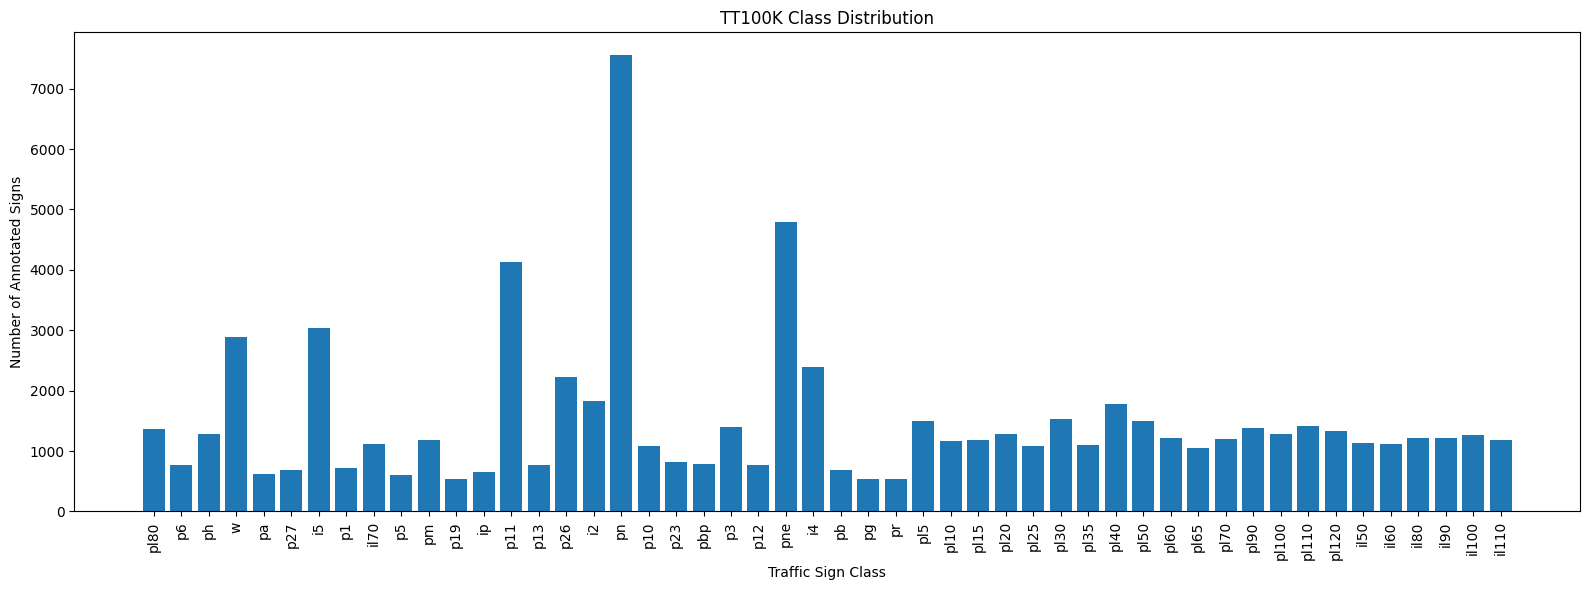

In [9]:
from collections import Counter
import matplotlib.pyplot as plt

class_names = config["names"]
class_counts = Counter()
total_objects = 0

# Read both training and validation annotations
for label_dir in [TRAIN_LABEL, VAL_LABEL]:
    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) >= 5:
                    class_id = int(parts[0])
                    class_counts[class_id] += 1
                    total_objects += 1

print(f"Total annotated traffic signs: {total_objects:,}")
print(f"Number of classes: {len(class_names)}")
print()

print("Objects per class:")
for class_id, name in enumerate(class_names):
    print(f"{class_id:2d} | {name:6s} | {class_counts[class_id]:,}")

# Plot
names = [class_names[i] for i in range(len(class_names))]
counts = [class_counts[i] for i in range(len(class_names))]

plt.figure(figsize=(16, 6))
plt.bar(names, counts)
plt.xlabel("Traffic Sign Class")
plt.ylabel("Number of Annotated Signs")
plt.title("TT100K Class Distribution")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Image Resolution and Format Analysis

In [10]:
from PIL import Image
from collections import Counter

resolution_counts = Counter()

all_images = train_images + val_images

for img_path in all_images:
    with Image.open(img_path) as img:
        resolution_counts[img.size] += 1

print(f"Total images checked: {len(all_images):,}")
print(f"Number of different resolutions: {len(resolution_counts)}")
print()

print("Resolution distribution:")
for resolution, count in resolution_counts.most_common():
    print(f"{resolution[0]} x {resolution[1]} : {count:,} images")

Total images checked: 24,221
Number of different resolutions: 1

Resolution distribution:
2048 x 2048 : 24,221 images


## Bounding Box Analysis

In [13]:
import numpy as np

bbox_widths = []
bbox_heights = []
bbox_areas = []

# YOLO format:
# class_id x_center y_center width height
# width and height are normalized between 0 and 1

for label_dir in [TRAIN_LABEL, VAL_LABEL]:
    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) >= 5:
                    w = float(parts[3])
                    h = float(parts[4])

                    # Convert normalized dimensions to pixels
                    width_px = w * 2048
                    height_px = h * 2048

                    bbox_widths.append(width_px)
                    bbox_heights.append(height_px)
                    bbox_areas.append(width_px * height_px)

bbox_widths = np.array(bbox_widths)
bbox_heights = np.array(bbox_heights)
bbox_areas = np.array(bbox_areas)

print(f"Bounding boxes analyzed: {len(bbox_widths):,}")
print()

print("Width (pixels)")
print(f"  Min:    {bbox_widths.min():.1f}")
print(f"  Median: {np.median(bbox_widths):.1f}")
print(f"  Mean:   {bbox_widths.mean():.1f}")
print(f"  Max:    {bbox_widths.max():.1f}")

print("\nHeight (pixels)")
print(f"  Min:    {bbox_heights.min():.1f}")
print(f"  Median: {np.median(bbox_heights):.1f}")
print(f"  Mean:   {bbox_heights.mean():.1f}")
print(f"  Max:    {bbox_heights.max():.1f}")

print("\nBounding-box area")
print(f"  Median: {np.median(bbox_areas):,.1f} pixels²")
print(f"  Mean:   {bbox_areas.mean():,.1f} pixels²")

# Percentage of relatively small signs
small = np.sum((bbox_widths < 32) | (bbox_heights < 32))
print(f"\nBoxes with width OR height < 32 px: {small:,}")
print(f"Percentage: {small / len(bbox_widths) * 100:.2f}%")

Bounding boxes analyzed: 74,008

Width (pixels)
  Min:    2.0
  Median: 36.0
  Mean:   45.5
  Max:    437.6

Height (pixels)
  Min:    6.1
  Median: 40.0
  Mean:   49.4
  Max:    465.4

Bounding-box area
  Median: 1,443.5 pixels²
  Mean:   3,191.5 pixels²

Boxes with width OR height < 32 px: 32,249
Percentage: 43.58%


## Duplicate Image Analysis

In [15]:
import hashlib
from collections import defaultdict

hash_to_images = defaultdict(list)

for img_path in all_images:
    with open(img_path, "rb") as f:
        image_hash = hashlib.md5(f.read()).hexdigest()

    hash_to_images[image_hash].append(img_path.name)

duplicate_groups = {
    h: names
    for h, names in hash_to_images.items()
    if len(names) > 1
}

duplicate_image_count = sum(
    len(names) - 1 for names in duplicate_groups.values()
)

print("Duplicate Image Analysis")
print("------------------------")
print(f"Images checked:          {len(all_images):,}")
print(f"Duplicate groups:        {len(duplicate_groups):,}")
print(f"Extra duplicate images: {duplicate_image_count:,}")

if duplicate_groups:
    print("\nExample duplicate groups:")
    for names in list(duplicate_groups.values())[:10]:
        print(names)

Duplicate Image Analysis
------------------------
Images checked:          24,221
Duplicate groups:        0
Extra duplicate images: 0


## Sample Images and Annotations

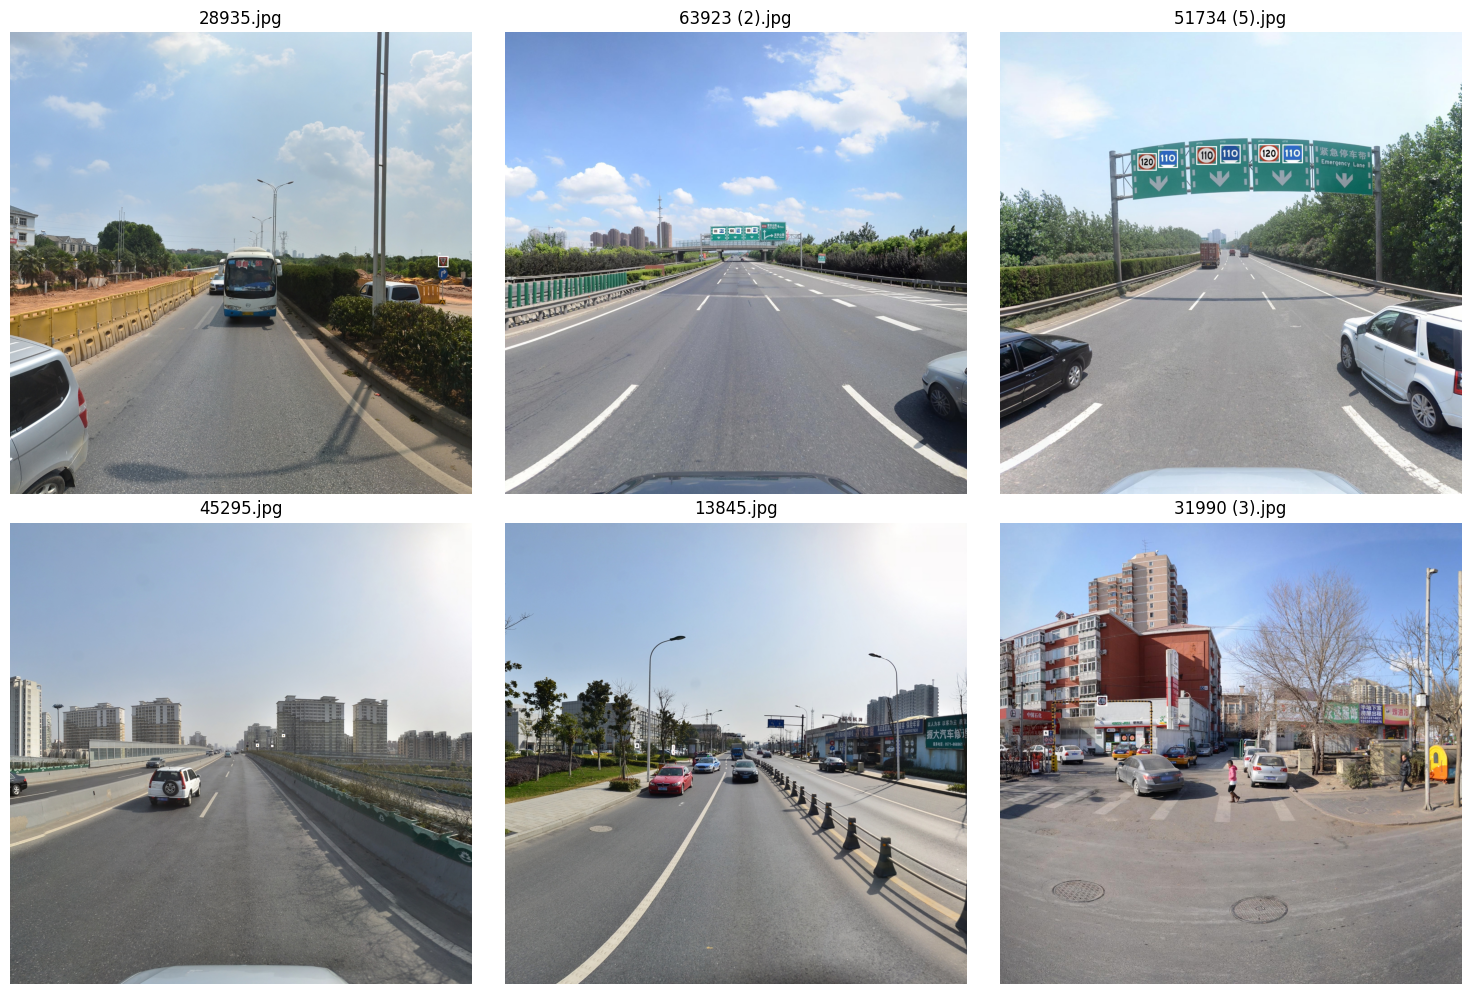

In [18]:
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

random.seed(42)

sample_images = random.sample(train_images, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, img_path in zip(axes.flatten(), sample_images):

    image = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    label_path = TRAIN_LABEL / f"{img_path.stem}.txt"

    with open(label_path, "r") as f:
        for line in f:
            class_id, xc, yc, w, h = map(float, line.split())

            class_id = int(class_id)

            img_w, img_h = image.size

            x1 = (xc - w / 2) * img_w
            y1 = (yc - h / 2) * img_h
            x2 = (xc + w / 2) * img_w
            y2 = (yc + h / 2) * img_h

            draw.rectangle([x1, y1, x2, y2], width=5)

            draw.text(
                (x1, max(0, y1 - 20)),
                class_names[class_id]
            )

    ax.imshow(image)
    ax.set_title(img_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Annotation Quality Check

In [21]:
invalid_boxes = []
very_tiny_boxes = []

for label_dir in [TRAIN_LABEL, VAL_LABEL]:
    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line_num, line in enumerate(f, start=1):
                parts = line.strip().split()

                if len(parts) != 5:
                    invalid_boxes.append((label_file.name, line_num, "Wrong format"))
                    continue

                class_id, xc, yc, w, h = map(float, parts)

                # Check class ID
                if not (0 <= int(class_id) < len(class_names)):
                    invalid_boxes.append((label_file.name, line_num, "Invalid class"))

                # Check YOLO normalized coordinates
                if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1):
                    invalid_boxes.append((label_file.name, line_num, "Invalid coordinates"))

                # Extremely tiny: less than 5 px in either dimension
                if w * 2048 < 5 or h * 2048 < 5:
                    very_tiny_boxes.append(
                        (label_file.name, int(class_id), w * 2048, h * 2048)
                    )

print("Annotation Quality Check")
print("------------------------")
print(f"Invalid annotations:       {len(invalid_boxes):,}")
print(f"Extremely tiny boxes:      {len(very_tiny_boxes):,}")

if invalid_boxes:
    print("\nExamples of invalid annotations:")
    for item in invalid_boxes[:10]:
        print(item)

if very_tiny_boxes:
    print("\nExamples of extremely tiny boxes:")
    for item in very_tiny_boxes[:10]:
        print(item)

Annotation Quality Check
------------------------
Invalid annotations:       0
Extremely tiny boxes:      1

Examples of extremely tiny boxes:
('5328.txt', 15, 2.000896, 7.000064)


## Visual Dataset Challenges

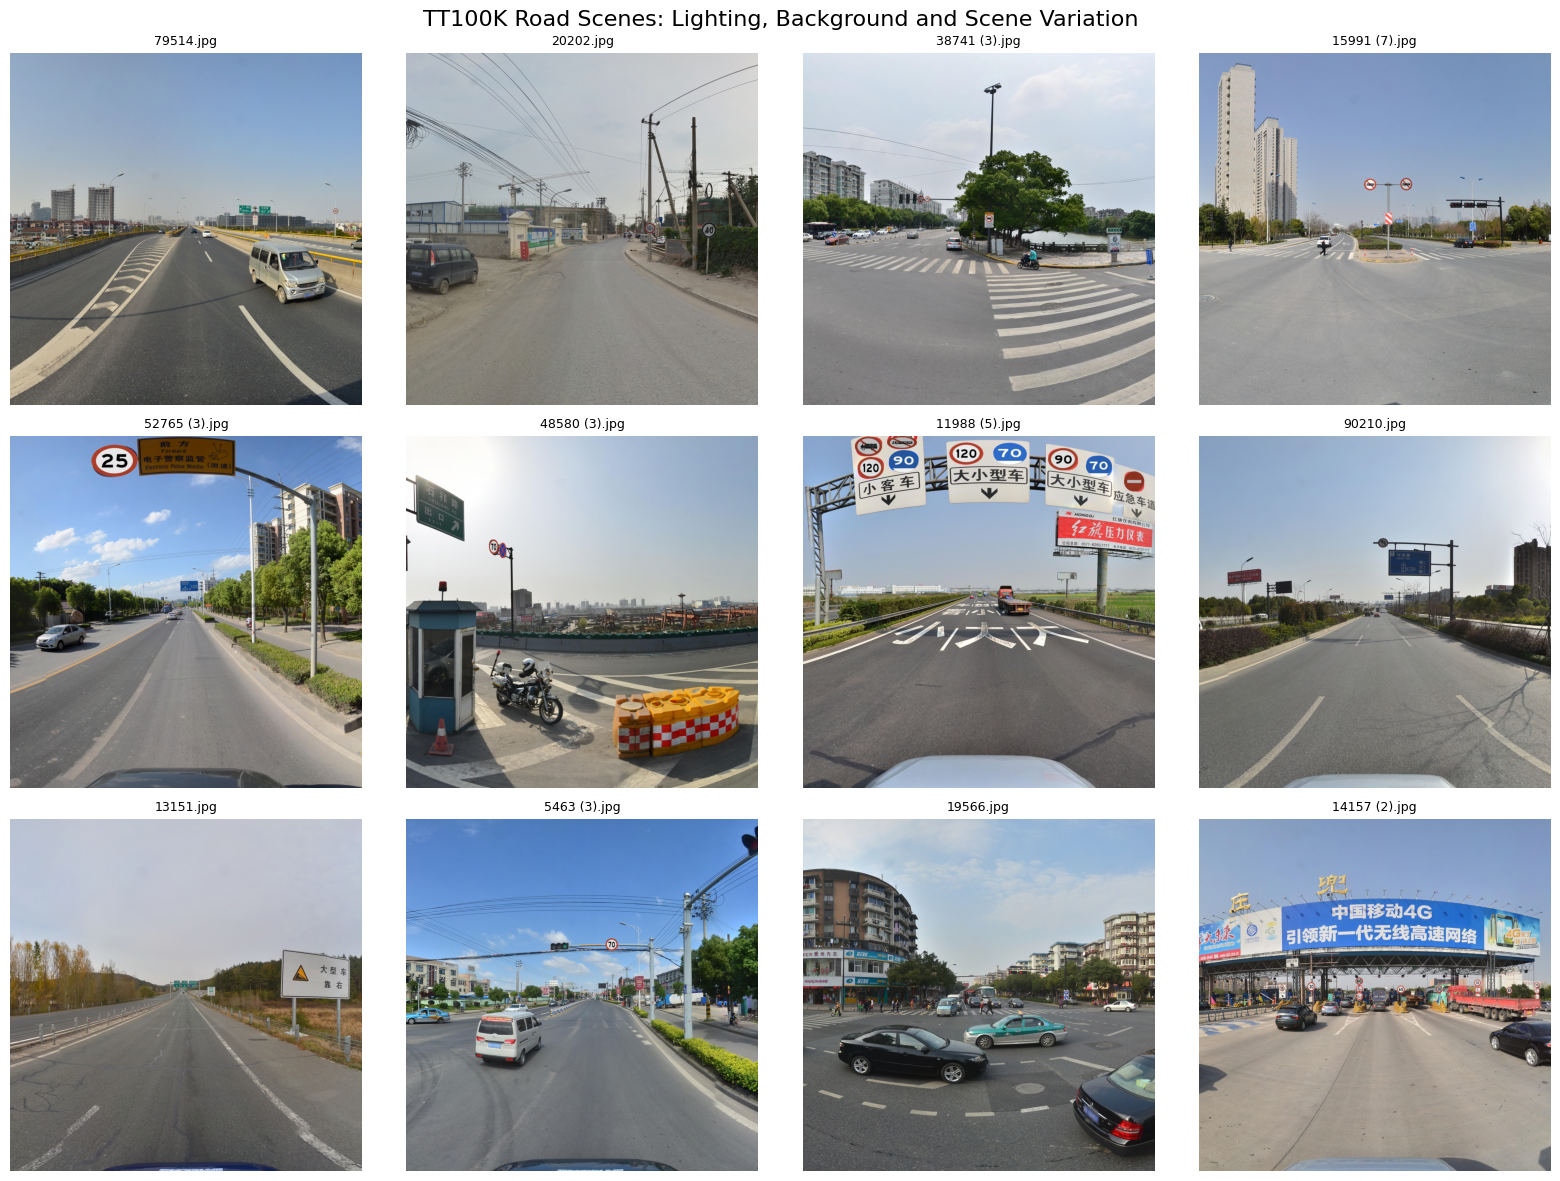

In [23]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(10)
challenge_samples = random.sample(all_images, 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, img_path in zip(axes.flatten(), challenge_samples):
    image = Image.open(img_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.suptitle(
    "TT100K Road Scenes: Lighting, Background and Scene Variation",
    fontsize=16
)
plt.tight_layout()
plt.show()

### Dataset Challenges

The exploration of this TT100K version reveals several important challenges:

- **Class imbalance:** The 50 classes are not equally represented. The most frequent class (`pn`) contains 7,554 instances, while the least frequent (`p19`) contains 535, giving an imbalance ratio of approximately **14.12×**.

- **Small objects:** Traffic signs occupy a very small part of the original 2048×2048 road images. The median bounding box is approximately **36×40 pixels**, and **43.58%** of all annotated signs have a width or height below 32 pixels. This makes small-object detection a major challenge.

- **Background and scene variation:** The dataset contains different road environments including highways, intersections, urban roads, roadside buildings, vegetation, traffic, and different illumination conditions. This increases visual variability around the traffic signs.

- **Occlusion and motion blur:** These may occur in real road scenes, but they are not explicitly annotated by this dataset and were not quantitatively measured in this exploration.

- **Domain shift:** TT100K contains road scenes collected in China. A model intended for deployment in another country, such as Egypt, may encounter different sign designs, road layouts, language, infrastructure, weather, and driving environments. Performance on TT100K therefore may not directly represent performance under the final deployment conditions.

- **Annotation quality and label noise:** All **74,008** inspected annotations followed valid YOLO formatting and contained valid normalized coordinates. Only one extremely small bounding box was found (approximately 2×7 pixels). However, this structural check cannot determine whether every class label is semantically correct, so possible label noise cannot be completely ruled out.

- **Duplicate images:** No exact duplicate images were found among the **24,221** images using file-hash comparison. This check detects exact duplicates but does not rule out visually similar or near-duplicate frames.

In [25]:
counts = [class_counts[i] for i in range(len(class_names))]

max_class = max(range(len(class_names)), key=lambda i: class_counts[i])
min_class = min(range(len(class_names)), key=lambda i: class_counts[i])

print("Class Imbalance Summary")
print("-----------------------")
print(f"Most frequent class:  {class_names[max_class]} "
      f"({class_counts[max_class]:,} instances)")

print(f"Least frequent class: {class_names[min_class]} "
      f"({class_counts[min_class]:,} instances)")

print(f"Imbalance ratio:      "
      f"{class_counts[max_class] / class_counts[min_class]:.2f}x")

print(f"Mean instances/class: {sum(counts) / len(counts):,.1f}")
print(f"Median instances/class: {np.median(counts):,.1f}")

Class Imbalance Summary
-----------------------
Most frequent class:  pn (7,554 instances)
Least frequent class: p19 (535 instances)
Imbalance ratio:      14.12x
Mean instances/class: 1,480.2
Median instances/class: 1,193.0


### YOLO Annotation Format

Each traffic sign is represented by one row in its corresponding label file:

`class_id  x_center  y_center  width  height`

The bounding-box coordinates are normalized relative to the image width and height.

In [27]:
# Show a real annotation file from TT100K

example_label = train_labels[0]

print("Label file:", example_label.name)
print("\nRaw annotation contents:\n")

with open(example_label, "r") as f:
    lines = f.readlines()

for line in lines:
    class_id, xc, yc, w, h = line.strip().split()

    print("Raw:", line.strip())
    print(f"  Class ID:   {class_id}")
    print(f"  Class name: {class_names[int(class_id)]}")
    print(f"  x_center:   {xc}")
    print(f"  y_center:   {yc}")
    print(f"  width:      {w}")
    print(f"  height:     {h}")
    print()

Label file: 84711.txt

Raw annotation contents:

Raw: 23 0.309254 0.477153 0.009789 0.009385
  Class ID:   23
  Class name: pne
  x_center:   0.309254
  y_center:   0.477153
  width:      0.009789
  height:     0.009385

Raw: 33 0.635562 0.449979 0.009024 0.009023
  Class ID:   33
  Class name: pl30
  x_center:   0.635562
  y_center:   0.449979
  width:      0.009024
  height:     0.009023

Raw: 17 0.646 0.449714 0.00867 0.009553
  Class ID:   17
  Class name: pn
  x_center:   0.646
  y_center:   0.449714
  width:      0.00867
  height:     0.009553



### Sample from Each Class

The following grid displays one annotated traffic-sign instance from each of the 50 classes. 
Each sample is cropped directly from its ground-truth bounding box.

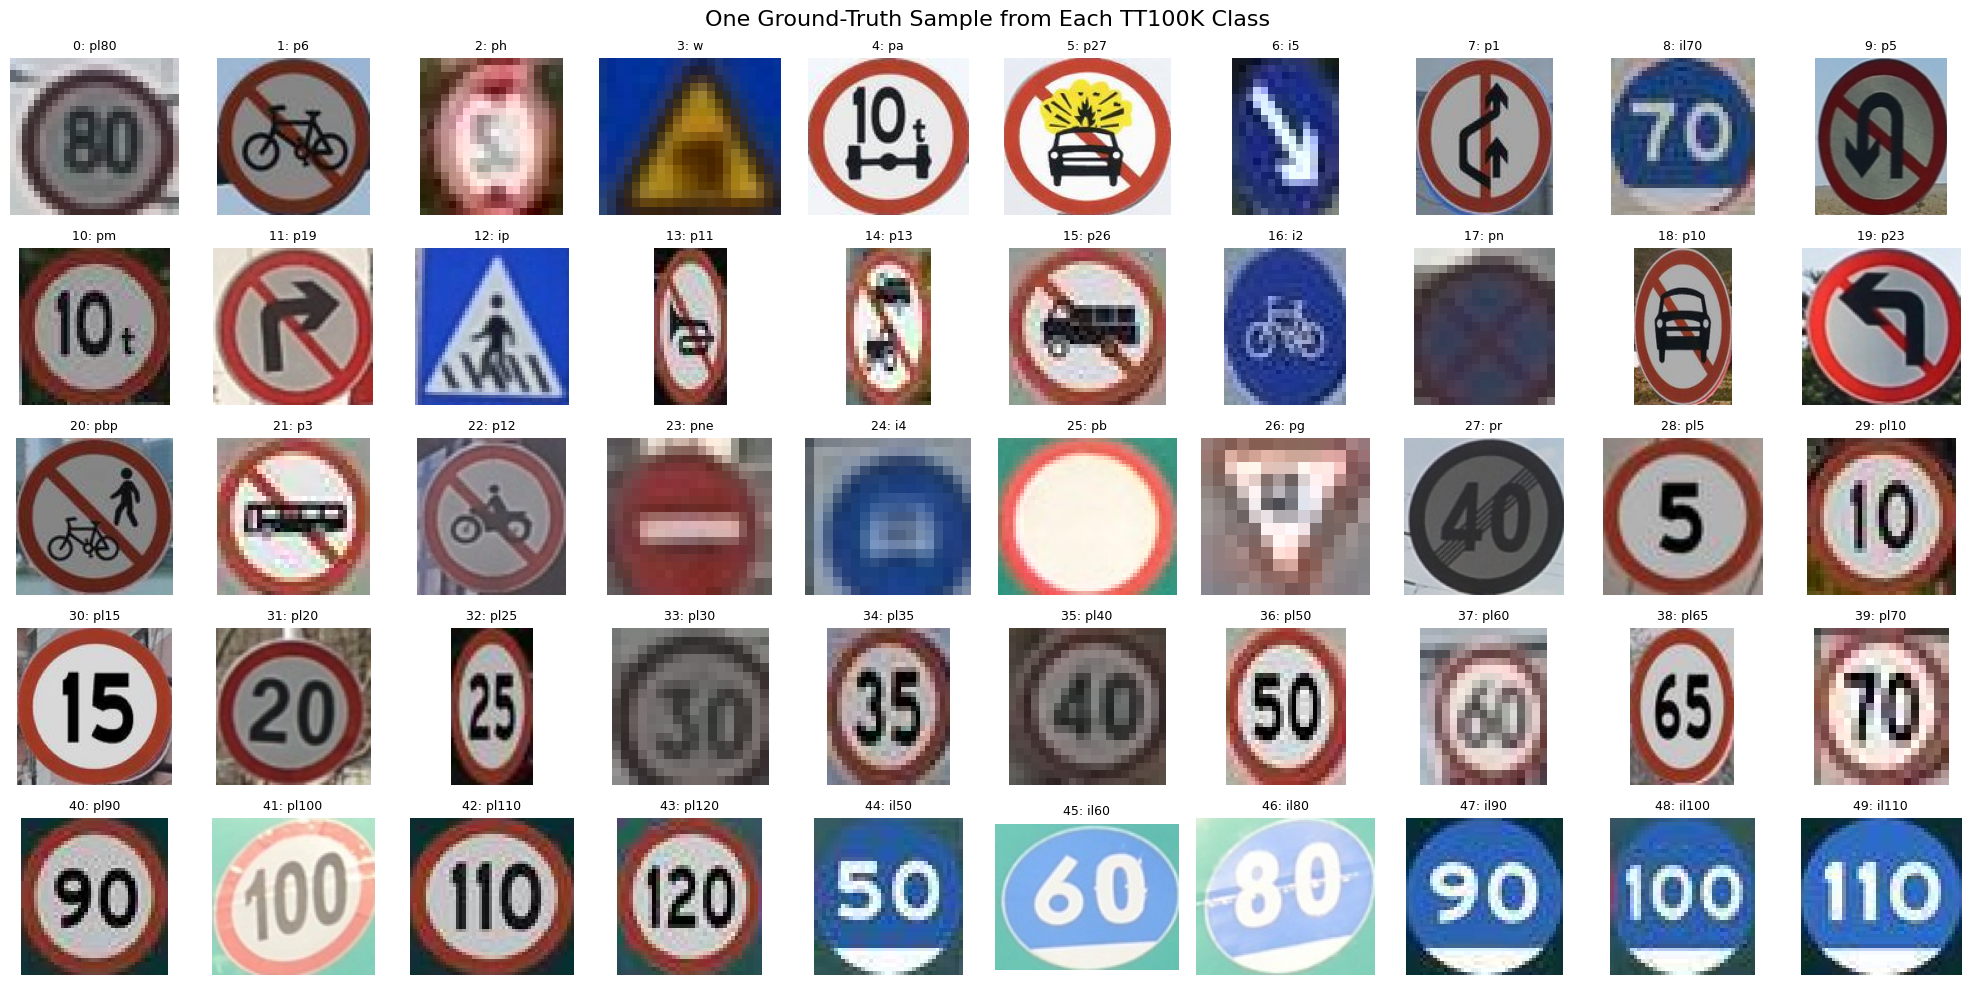

Classes represented: 50/50


In [29]:
from PIL import Image
import matplotlib.pyplot as plt

def crop_yolo_box(image, xc, yc, w, h):
    """Crop a YOLO-format bounding box from a PIL image."""
    
    img_w, img_h = image.size

    x1 = max(0, int((xc - w / 2) * img_w))
    y1 = max(0, int((yc - h / 2) * img_h))
    x2 = min(img_w, int((xc + w / 2) * img_w))
    y2 = min(img_h, int((yc + h / 2) * img_h))

    return image.crop((x1, y1, x2, y2))


# Find one example for each class
class_samples = {}

for label_file in train_labels:
    if len(class_samples) == len(class_names):
        break

    img_path = TRAIN_IMG / f"{label_file.stem}.jpg"

    if not img_path.exists():
        continue

    with open(label_file, "r") as f:
        for line in f:
            class_id, xc, yc, w, h = map(float, line.split())
            class_id = int(class_id)

            if class_id not in class_samples:
                class_samples[class_id] = (
                    img_path,
                    xc, yc, w, h
                )


# Display one crop per class
fig, axes = plt.subplots(5, 10, figsize=(20, 10))

for class_id, ax in enumerate(axes.flatten()):
    if class_id in class_samples:
        img_path, xc, yc, w, h = class_samples[class_id]

        image = Image.open(img_path).convert("RGB")
        crop = crop_yolo_box(image, xc, yc, w, h)

        ax.imshow(crop)
        ax.set_title(
            f"{class_id}: {class_names[class_id]}",
            fontsize=9
        )

    ax.axis("off")

plt.suptitle("One Ground-Truth Sample from Each TT100K Class", fontsize=16)
plt.tight_layout()
plt.show()

print(f"Classes represented: {len(class_samples)}/{len(class_names)}")

## Set Up the yolo Model
the yolo model detects the position of the sign

In [11]:
import yaml

SRC = "/kaggle/input/datasets/braunge/tt100k/mydata"

# read the class names from the dataset's own YAML
orig = yaml.safe_load(open(f"{SRC}/YOLOv8_TT100K.yaml"))
class_names = orig["names"]
print(len(class_names), class_names[:5])

yaml.safe_dump({"path": SRC, "train": "images/train", "val": "images/val",
                "nc": len(class_names), "names": class_names},
               open("/kaggle/working/tt100k.yaml", "w"), sort_keys=False)

print(open("/kaggle/working/tt100k.yaml").read()[:300])

50 ['pl80', 'p6', 'ph', 'w', 'pa']
path: /kaggle/input/datasets/braunge/tt100k/mydata
train: images/train
val: images/val
nc: 50
names:
- pl80
- p6
- ph
- w
- pa
- p27
- i5
- p1
- il70
- p5
- pm
- p19
- ip
- p11
- p13
- p26
- i2
- pn
- p10
- p23
- pbp
- p3
- p12
- pne
- i4
- pb
- pg
- pr
- pl5
- pl10
- pl15
- pl20
- pl25
- pl30
- pl3


initialising hugingface repo to save model

In [14]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, HfApi


login(UserSecretsClient().get_secret("huggingface"))

HF_REPO = "youssefhazem/yolov8s-tt100k"
api = HfApi()
api.create_repo(HF_REPO, repo_type="model", private=False, exist_ok=True)

RepoUrl('https://huggingface.co/youssefhazem/yolov8s-tt100k', endpoint='https://huggingface.co', repo_type='model', repo_id='youssefhazem/yolov8s-tt100k')

## image croping
using the position from the yolo model the image is cropped to only have the sign to be fed to the vit model

## Set Up the vit Model
For this project we are going to be using the "google/vit-base-patch16-224-in21k" pretrained transformer.

In [ ]:
from transformers import ViTImageProcessor, ViTForImageClassification

model_name_or_path = 'google/vit-base-patch16-224-in21k'
processor = ViTImageProcessor.from_pretrained(model_name_or_path)
model = ViTForImageClassification.from_pretrained(
    model_name_or_path,
    num_labels=len(id2label),
    id2label=id2label,
    label2id=label2id
)

Let's take a look at how the processor represents the data. It generates a `pixel_values` tensor of patches (numeric representation of the image), that the model has been pretrained to understand.

In [ ]:
processor(split_dataset['train'][123]['image'], return_tensors='pt')

Now, let's apply this preprocessing on all of our training images. I use `with_transform` since it only applies the changes to the data entry once we index it, which saves us time when dealing with such a big dataset as GTSRB.

In [ ]:
def process_data(example_batch):
    inputs = processor([x for x in example_batch['image']], return_tensors='pt')
    inputs['labels'] = example_batch['label']
    return inputs

prepared_split_dataset = split_dataset.with_transform(process_data)

In [ ]:
import torch

def collate_fn(batch):
    return {
        'pixel_values': torch.stack([x['pixel_values'] for x in batch]),
        'labels': torch.tensor([x['labels'] for x in batch])
    }

In [ ]:
import numpy as np
from datasets import load_metric

metric = load_metric("accuracy")
def compute_metrics(p):
    return metric.compute(predictions=np.argmax(p.predictions, axis=1), references=p.label_ids)

### Train Model
Now, I use the `transformers` library to instantiate the `TrainingArguments` for this training job, and then use the `Trainer` class to perform the actual training and save the final model. I use `wandb` as a reporting tool so I can follow the training metrics while the job is completing.

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
  output_dir="./vit-traffic-signs",
  per_device_train_batch_size=4,
  evaluation_strategy="steps",
  num_train_epochs=2,
  fp16=False,
  save_steps=100,
  eval_steps=100,
  logging_steps=10,
  learning_rate=2e-4,
  save_total_limit=2,
  remove_unused_columns=False,
  push_to_hub=False,
  report_to='wandb',
  load_best_model_at_end=True,
)

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    train_dataset=prepared_split_dataset["train"],
    eval_dataset=prepared_split_dataset["val"],
    tokenizer=processor,
)

In [ ]:
trainer.train()

### Save Trained Model

In [ ]:
trainer.save_model('./final_model')